Land rows: 409  | Floating rows: 576
  seed=1: val R2=0.0993
  seed=2: val R2=0.7551
  seed=3: val R2=0.7923
  seed=42: val R2=0.7899
  seed=100: val R2=0.8296
Best land seed selected with val R2=0.8296
  seed=1: val R2=0.6105
  seed=2: val R2=0.8482
  seed=3: val R2=0.8466
  seed=42: val R2=0.6049
  seed=100: val R2=0.6287
Best floating seed selected with val R2=0.8482

========== TRAINING METRICS ==========
LAND TRAIN -> R2: 0.9335 | RMSE: 0.0528 | MAE: 0.0411
FLOATING TRAIN -> R2: 0.9370 | RMSE: 0.0510 | MAE: 0.0387

========== TESTING METRICS ==========
LAND TEST -> R2: 0.8709 | RMSE: 0.0620 | MAE: 0.0428
FLOATING TEST -> R2: 0.9194 | RMSE: 0.0702 | MAE: 0.0499



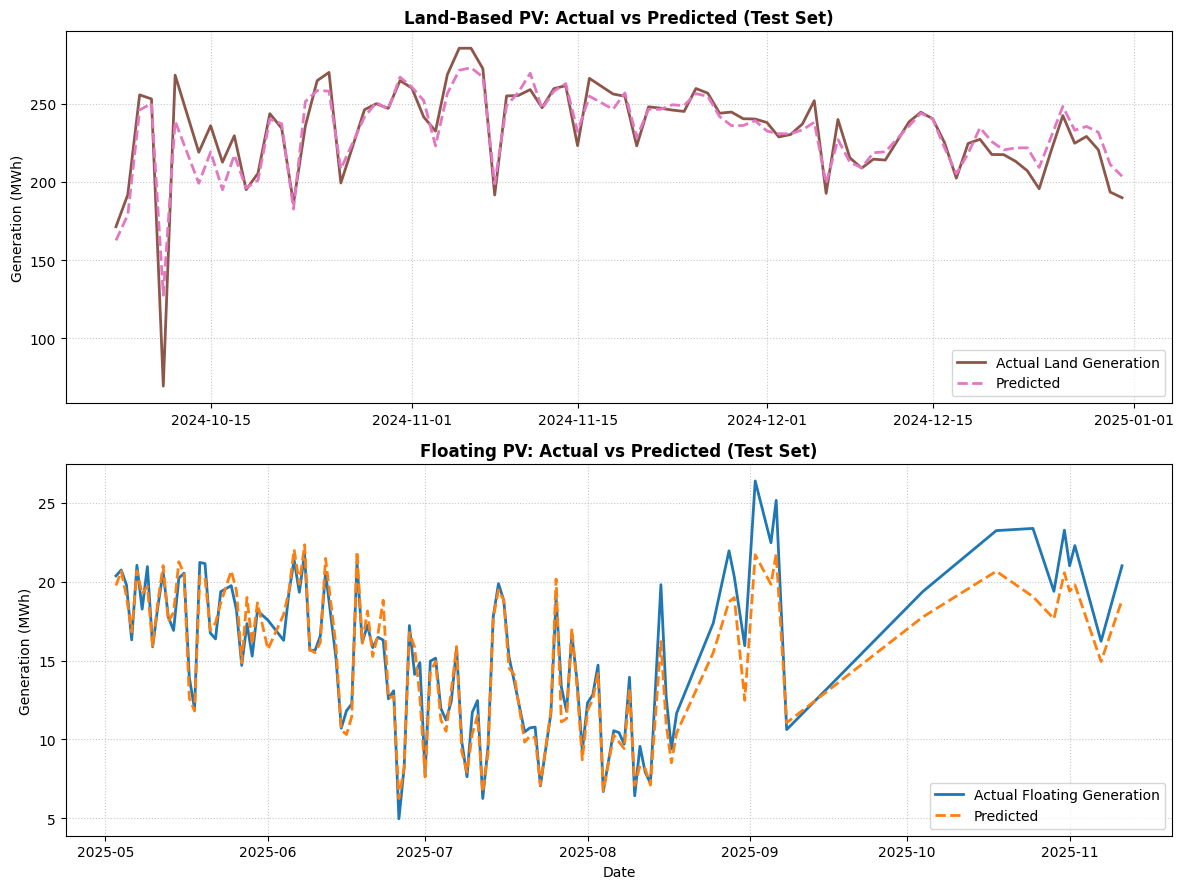

In [5]:
# ==========================================
# 1. CONFIGURATION
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import tensorflow as tf
import math

TARGET_LAND = 'LANDBASED_ENERGY_MWH'
TARGET_FPV = 'FLOATING_ENERGY_MWH'
T_STC = 25.0        # standard test condition temperature
ALPHA_P = -0.0035     # crystalline-silicon power temperature coefficient (literature value)
LAMBDA_PHYSICS = 0.1 # physics loss weight -- found optimal via grid search

np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# 2. LOAD DATASET
# ==========================================
df = pd.read_csv('merged_hybrid_generation_weather_filled.csv')
df['DATE'] = pd.to_datetime(df['DATE'])
df['MONTH'] = df['DATE'].dt.month

weather_cols = ['temperature_2m_max (°C)', 'wind_speed_10m_max (km/h)',
                'relative_humidity_2m_max (%)', 'shortwave_radiation_sum (MJ/m²)']

# ==========================================
# 3. DYNAMIC EFFICIENCY FILTRATION (IQR)
# ==========================================
df_land = df[df[TARGET_LAND] > 0].copy()
df_land['EFF_LAND'] = df_land[TARGET_LAND] / df_land['GLOBAL_IRRADIATION_WH_M2']
Q1_L, Q3_L = df_land['EFF_LAND'].quantile(0.25), df_land['EFF_LAND'].quantile(0.75)
IQR_L = Q3_L - Q1_L
df_land = df_land[(df_land['EFF_LAND'] >= (Q1_L - 1.0 * IQR_L)) & (df_land['EFF_LAND'] <= (Q3_L + 1.0 * IQR_L))]

df_fpv = df[df[TARGET_FPV] > 0].copy()
df_fpv['EFF_FPV'] = df_fpv[TARGET_FPV] / df_fpv['GLOBAL_IRRADIATION_WH_M2']
Q1_F, Q3_F = df_fpv['EFF_FPV'].quantile(0.25), df_fpv['EFF_FPV'].quantile(0.75)
IQR_F = Q3_F - Q1_F
df_fpv = df_fpv[(df_fpv['EFF_FPV'] >= (Q1_F - 1.0 * IQR_F)) & (df_fpv['EFF_FPV'] <= (Q3_F + 1.0 * IQR_F))]

# ==========================================
# 4. FEATURE ENGINEERING (per plant, NO merge)
# ==========================================
# df_land and df_fpv stay separate for the rest of the notebook -- each keeps
# its own full set of active days instead of being cut down to only the days
# both plants were active simultaneously.

df_land = df_land[['DATE', TARGET_LAND, 'GLOBAL_IRRADIATION_WH_M2', 'SUNSHINE_TIME_MIN',
                    'MONTH', 'HOURS_RUN_HRS'] + weather_cols].copy().sort_values('DATE').reset_index(drop=True)
df_fpv = df_fpv[['DATE', TARGET_FPV, 'GLOBAL_IRRADIATION_WH_M2', 'SUNSHINE_TIME_MIN',
                  'MONTH', 'HOURS_RUN_HRS'] + weather_cols].copy().sort_values('DATE').reset_index(drop=True)

df_land['SOLAR_INTENSITY'] = df_land['GLOBAL_IRRADIATION_WH_M2'] / (df_land['SUNSHINE_TIME_MIN'] + 1)
df_fpv['SOLAR_INTENSITY'] = df_fpv['GLOBAL_IRRADIATION_WH_M2'] / (df_fpv['SUNSHINE_TIME_MIN'] + 1)

df_land['MONTH_SIN'] = np.sin(2 * np.pi * df_land['MONTH'] / 12)
df_land['MONTH_COS'] = np.cos(2 * np.pi * df_land['MONTH'] / 12)
df_fpv['MONTH_SIN'] = np.sin(2 * np.pi * df_fpv['MONTH'] / 12)
df_fpv['MONTH_COS'] = np.cos(2 * np.pi * df_fpv['MONTH'] / 12)

# Lag feature instead of same-day target -- this replaces the leak
df_land['Lag1'] = df_land[TARGET_LAND].shift(1)
df_fpv['Lag1'] = df_fpv[TARGET_FPV].shift(1)
df_land = df_land.dropna().reset_index(drop=True)
df_fpv = df_fpv.dropna().reset_index(drop=True)

land_features = ['GLOBAL_IRRADIATION_WH_M2', 'SUNSHINE_TIME_MIN', 'MONTH_SIN', 'MONTH_COS',
                  'HOURS_RUN_HRS', 'SOLAR_INTENSITY', 'Lag1'] + weather_cols
fpv_features = land_features  # same feature set, different underlying data

print("Land rows:", len(df_land), " | Floating rows:", len(df_fpv))

# ==========================================
# 5. TRAIN/VAL/TEST SPLIT, SCALING & PHYSICS TARGET (per plant)
# ==========================================
def prepare_split(df_plant, feature_cols, target_col):
    n = len(df_plant)
    train_end = int(n * 0.6)
    val_end = int(n * 0.8)

    # Physics target (adapted Sandia-style equation), calibrated on TRAINING data only
    eff_cal = (df_plant[target_col].iloc[:train_end] / df_plant['GLOBAL_IRRADIATION_WH_M2'].iloc[:train_end]).median()
    G = df_plant['GLOBAL_IRRADIATION_WH_M2'].values
    T = df_plant['temperature_2m_max (°C)'].values
    physics_all = np.maximum(eff_cal * G * (1 + ALPHA_P * (T - T_STC)), 0)

    X_all = df_plant[feature_cols].values
    y_all = df_plant[target_col].values.reshape(-1, 1)

    X_train_raw, X_val_raw, X_test_raw = X_all[:train_end], X_all[train_end:val_end], X_all[val_end:]
    y_train_raw, y_val_raw, y_test_raw = y_all[:train_end], y_all[train_end:val_end], y_all[val_end:]
    phys_train_raw = physics_all[:train_end].reshape(-1, 1)
    phys_val_raw = physics_all[train_end:val_end].reshape(-1, 1)
    dates_test = df_plant['DATE'].iloc[val_end:].values

    scaler_X = MinMaxScaler(); X_train = scaler_X.fit_transform(X_train_raw)
    X_val = scaler_X.transform(X_val_raw); X_test = scaler_X.transform(X_test_raw)
    scaler_y = MinMaxScaler(); y_train = scaler_y.fit_transform(y_train_raw)
    y_val = scaler_y.transform(y_val_raw); y_test = scaler_y.transform(y_test_raw)
    phys_train = scaler_y.transform(phys_train_raw)
    phys_val = scaler_y.transform(phys_val_raw)

    # Single-day input (no window) -- reshape to (n, 1, n_features) for Conv1D/LSTM
    X_train = X_train.reshape(-1, 1, X_train.shape[1])
    X_val = X_val.reshape(-1, 1, X_val.shape[1])
    X_test = X_test.reshape(-1, 1, X_test.shape[1])

    y_train_combined = np.concatenate([y_train, phys_train], axis=1)
    y_val_combined = np.concatenate([y_val, phys_val], axis=1)

    return (X_train, X_val, X_test, y_train, y_val, y_test,
            y_train_combined, y_val_combined, scaler_y, dates_test)

(Xl_train, Xl_val, Xl_test, yl_train, yl_val, yl_test,
 yl_train_c, yl_val_c, scaler_land, dates_test_land) = prepare_split(df_land, land_features, TARGET_LAND)

(Xf_train, Xf_val, Xf_test, yf_train, yf_val, yf_test,
 yf_train_c, yf_val_c, scaler_fpv, dates_test_fpv) = prepare_split(df_fpv, fpv_features, TARGET_FPV)

# ==========================================
# 6. ASYMMETRIC ARCHITECTURE (two separate models)
# ==========================================
def build_land_model(n_feat):   # deeper -- land is the more stable system
    inp = Input(shape=(1, n_feat), name='land_input')
    x = Conv1D(8, 1, activation='relu', padding='causal')(inp)
    x = LSTM(16, name='land_lstm')(x)
    x = Dense(16, activation='relu')(x)
    x = Dropout(0.1)(x)
    out = Dense(1, activation='linear', name='land_output')(x)
    return Model(inputs=inp, outputs=out)

def build_fpv_model(n_feat):    # shallower -- floating is noisier, needs more regularization
    inp = Input(shape=(1, n_feat), name='fpv_input')
    x = Conv1D(8, 1, activation='relu', padding='causal')(inp)
    x = LSTM(16, name='fpv_lstm')(x)
    x = Dropout(0.2)(x)
    out = Dense(1, activation='linear', name='fpv_output')(x)
    return Model(inputs=inp, outputs=out)

model_land = build_land_model(Xl_train.shape[2])
model_fpv = build_fpv_model(Xf_train.shape[2])

# ==========================================
# 7. PHYSICS-INFORMED LOSS
# ==========================================
def pinn_loss(y_true_and_phys, y_pred):
    y_true = y_true_and_phys[:, 0:1]
    phys = y_true_and_phys[:, 1:2]
    data_loss = tf.reduce_mean(tf.square(y_true - y_pred))
    physics_loss = tf.reduce_mean(tf.square(phys - y_pred))
    return data_loss + LAMBDA_PHYSICS * physics_loss

model_land.compile(optimizer=Adam(learning_rate=0.002), loss=pinn_loss)
model_fpv.compile(optimizer=Adam(learning_rate=0.002), loss=pinn_loss)

# ==========================================
# 8. TRAINING (two separate fits)
# ==========================================
# print("Training LAND model...")
# es_land = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
# rl_land = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-5)
# history_land = model_land.fit(Xl_train, yl_train_c, validation_data=(Xl_val, yl_val_c),
#                                epochs=120, batch_size=16, callbacks=[es_land, rl_land], verbose=1)

# print("Training FLOATING model...")
# es_fpv = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
# rl_fpv = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-5)
# history_fpv = model_fpv.fit(Xf_train, yf_train_c, validation_data=(Xf_val, yf_val_c),
#                              epochs=120, batch_size=16, callbacks=[es_fpv, rl_fpv], verbose=1)

# ==========================================
# 8a. LAND TRAINING (multi-seed, keep best by validation)
# ==========================================
best_val_r2 = -np.inf
best_model_land = None
best_history_land = None

for seed in [1, 2, 3, 42, 100]:
    np.random.seed(seed)
    tf.random.set_seed(seed)
    candidate = build_land_model(Xl_train.shape[2])
    candidate.compile(optimizer=Adam(learning_rate=0.002), loss=pinn_loss)
    es = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    rl = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-5)
    hist = candidate.fit(Xl_train, yl_train_c, validation_data=(Xl_val, yl_val_c),
                          epochs=120, batch_size=16, callbacks=[es, rl], verbose=0)
    val_pred = candidate.predict(Xl_val, verbose=0)
    val_r2 = r2_score(yl_val, val_pred)
    print(f"  seed={seed}: val R2={val_r2:.4f}")
    if val_r2 > best_val_r2:
        best_val_r2 = val_r2
        best_model_land = candidate
        best_history_land = hist

model_land = best_model_land
history_land = best_history_land
print(f"Best land seed selected with val R2={best_val_r2:.4f}")

# ==========================================
# 8b. FLOATING TRAINING (multi-seed, keep best by validation)
# ==========================================
best_val_r2_fpv = -np.inf
best_model_fpv = None
best_history_fpv = None

for seed in [1, 2, 3, 42, 100]:
    np.random.seed(seed)
    tf.random.set_seed(seed)
    candidate = build_fpv_model(Xf_train.shape[2])
    candidate.compile(optimizer=Adam(learning_rate=0.002), loss=pinn_loss)
    es = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    rl = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-5)
    hist = candidate.fit(Xf_train, yf_train_c, validation_data=(Xf_val, yf_val_c),
                          epochs=120, batch_size=16, callbacks=[es, rl], verbose=0)
    val_pred = candidate.predict(Xf_val, verbose=0)
    val_r2 = r2_score(yf_val, val_pred)
    print(f"  seed={seed}: val R2={val_r2:.4f}")
    if val_r2 > best_val_r2_fpv:
        best_val_r2_fpv = val_r2
        best_model_fpv = candidate
        best_history_fpv = hist

model_fpv = best_model_fpv
history_fpv = best_history_fpv
print(f"Best floating seed selected with val R2={best_val_r2_fpv:.4f}")


# ==========================================
# 9. EVALUATION & METRICS (training AND testing)
# ==========================================
def calc_normalized_metrics(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return r2, rmse, mae

def evaluate_and_print(model, X, y_scaled, label):
    pred = model.predict(X, verbose=0)
    r2, rmse, mae = calc_normalized_metrics(y_scaled, pred)
    print(f"{label} -> R2: {r2:.4f} | RMSE: {rmse:.4f} | MAE: {mae:.4f}")
    return pred

print("\n========== TRAINING METRICS ==========")
pred_land_train = evaluate_and_print(model_land, Xl_train, yl_train, "LAND TRAIN")
pred_fpv_train = evaluate_and_print(model_fpv, Xf_train, yf_train, "FLOATING TRAIN")

print("\n========== TESTING METRICS ==========")
pred_land_test = evaluate_and_print(model_land, Xl_test, yl_test, "LAND TEST")
pred_fpv_test = evaluate_and_print(model_fpv, Xf_test, yf_test, "FLOATING TEST")
print("=======================================\n")

# ==========================================
# 10. COMBINED PLOTTING
# ==========================================
y_test_real_land = scaler_land.inverse_transform(yl_test).flatten()
y_pred_real_land = scaler_land.inverse_transform(pred_land_test).flatten()
y_test_real_fpv = scaler_fpv.inverse_transform(yf_test).flatten()
y_pred_real_fpv = scaler_fpv.inverse_transform(pred_fpv_test).flatten()

plot_df_land = pd.DataFrame({'DATE': dates_test_land, 'ACT': y_test_real_land, 'PRED': y_pred_real_land}).sort_values('DATE')
plot_df_fpv = pd.DataFrame({'DATE': dates_test_fpv, 'ACT': y_test_real_fpv, 'PRED': y_pred_real_fpv}).sort_values('DATE')

fig, axes = plt.subplots(2, 1, figsize=(12, 9))
axes[0].plot(plot_df_land['DATE'], plot_df_land['ACT'], label='Actual Land Generation', color='#8c564b', linewidth=2)
axes[0].plot(plot_df_land['DATE'], plot_df_land['PRED'], label='Predicted', color='#e377c2', linestyle='--', linewidth=2)
axes[0].set_title('Land-Based PV: Actual vs Predicted (Test Set)', fontweight='bold')
axes[0].set_ylabel('Generation (MWh)'); axes[0].legend(loc='lower right'); axes[0].grid(True, linestyle=':', alpha=0.7)

axes[1].plot(plot_df_fpv['DATE'], plot_df_fpv['ACT'], label='Actual Floating Generation', color='#1f77b4', linewidth=2)
axes[1].plot(plot_df_fpv['DATE'], plot_df_fpv['PRED'], label='Predicted', color='#ff7f0e', linestyle='--', linewidth=2)
axes[1].set_title('Floating PV: Actual vs Predicted (Test Set)', fontweight='bold')
axes[1].set_ylabel('Generation (MWh)'); axes[1].set_xlabel('Date'); axes[1].legend(loc='lower right'); axes[1].grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

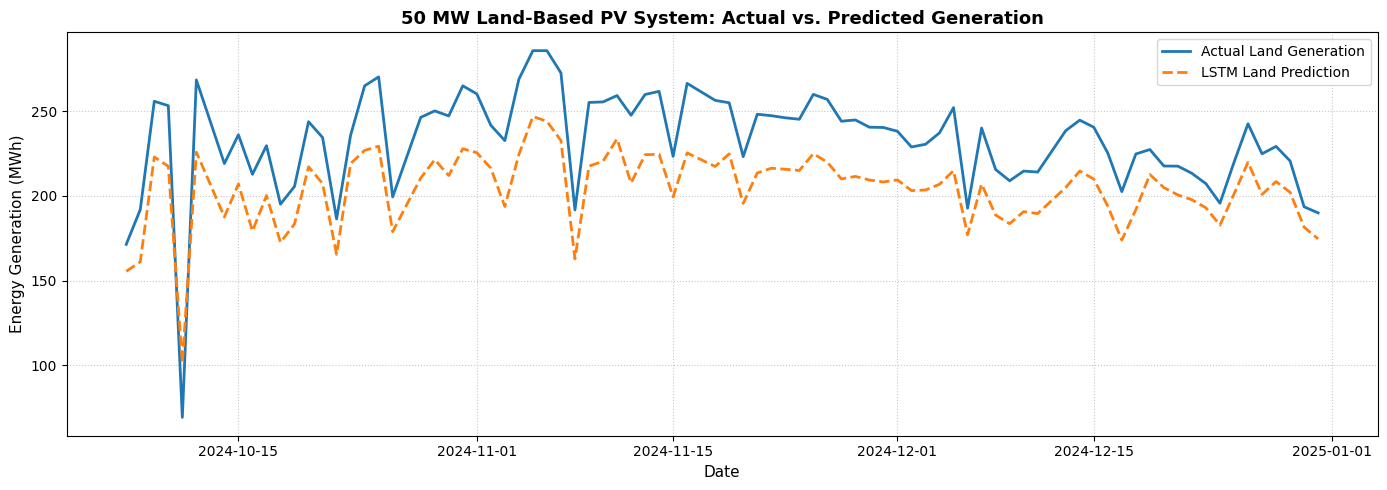

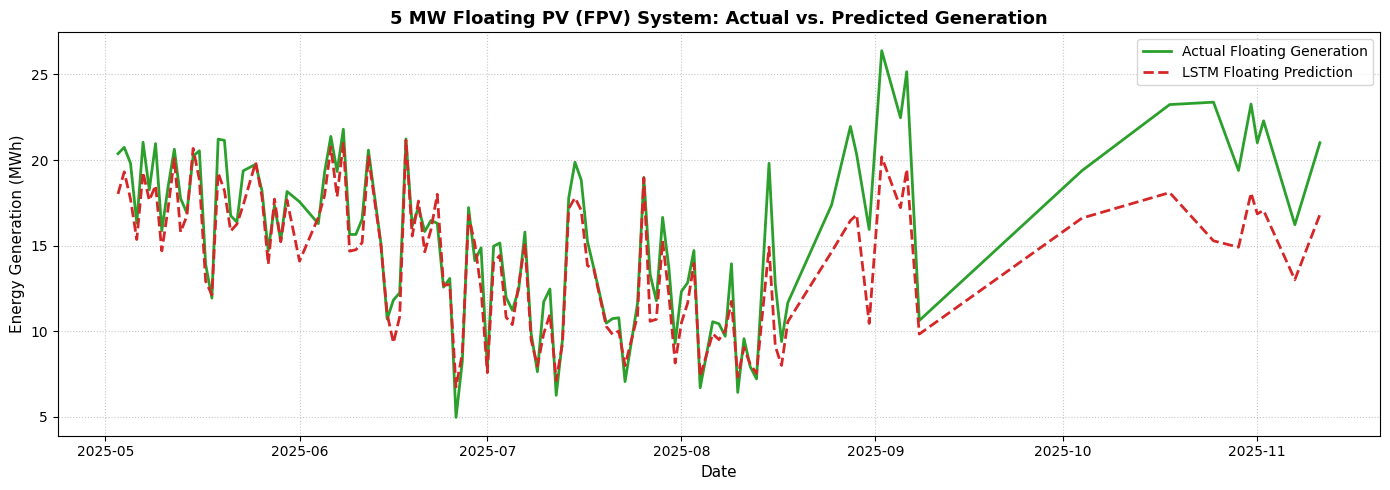

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

# ==========================================
# 11. INDIVIDUAL SYSTEM EVALUATION & PLOTTING
# ==========================================

# Inverse-transform each plant's test predictions back to real MWh values
y_test_real_land = scaler_land.inverse_transform(yl_test).flatten()
y_pred_real_land = scaler_land.inverse_transform(pred_land_test).flatten()
y_test_real_fpv = scaler_fpv.inverse_transform(yf_test).flatten()
y_pred_real_fpv = scaler_fpv.inverse_transform(pred_fpv_test).flatten()

# Two SEPARATE DataFrames -- land and floating no longer share the same test dates
df_results_land = pd.DataFrame({
    'DATE': dates_test_land,
    'ACT_LAND': y_test_real_land,
    'PRED_LAND': y_pred_real_land
}).sort_values(by='DATE')

df_results_fpv = pd.DataFrame({
    'DATE': dates_test_fpv,
    'ACT_FPV': y_test_real_fpv,
    'PRED_FPV': y_pred_real_fpv
}).sort_values(by='DATE')

# ----------------------------------------------------
# Plot 1: Land-Based PV (50 MW) Actual vs Predicted
# ----------------------------------------------------
plt.figure(figsize=(14, 5))
plt.plot(df_results_land['DATE'], df_results_land['ACT_LAND'], label='Actual Land Generation', color='#1f77b4', linewidth=2)
plt.plot(df_results_land['DATE'], df_results_land['PRED_LAND'], label='LSTM Land Prediction', color='#ff7f0e', linestyle='--', linewidth=2)
plt.title('50 MW Land-Based PV System: Actual vs. Predicted Generation', fontsize=13, fontweight='bold')
plt.ylabel('Energy Generation (MWh)', fontsize=11)
plt.xlabel('Date', fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

# ----------------------------------------------------
# Plot 2: Floating PV (5 MW) Actual vs Predicted
# ----------------------------------------------------
plt.figure(figsize=(14, 5))
plt.plot(df_results_fpv['DATE'], df_results_fpv['ACT_FPV'], label='Actual Floating Generation', color='#2ca02c', linewidth=2)
plt.plot(df_results_fpv['DATE'], df_results_fpv['PRED_FPV'], label='LSTM Floating Prediction', color='#d62728', linestyle='--', linewidth=2)
plt.title('5 MW Floating PV (FPV) System: Actual vs. Predicted Generation', fontsize=13, fontweight='bold')
plt.ylabel('Energy Generation (MWh)', fontsize=11)
plt.xlabel('Date', fontsize=11)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

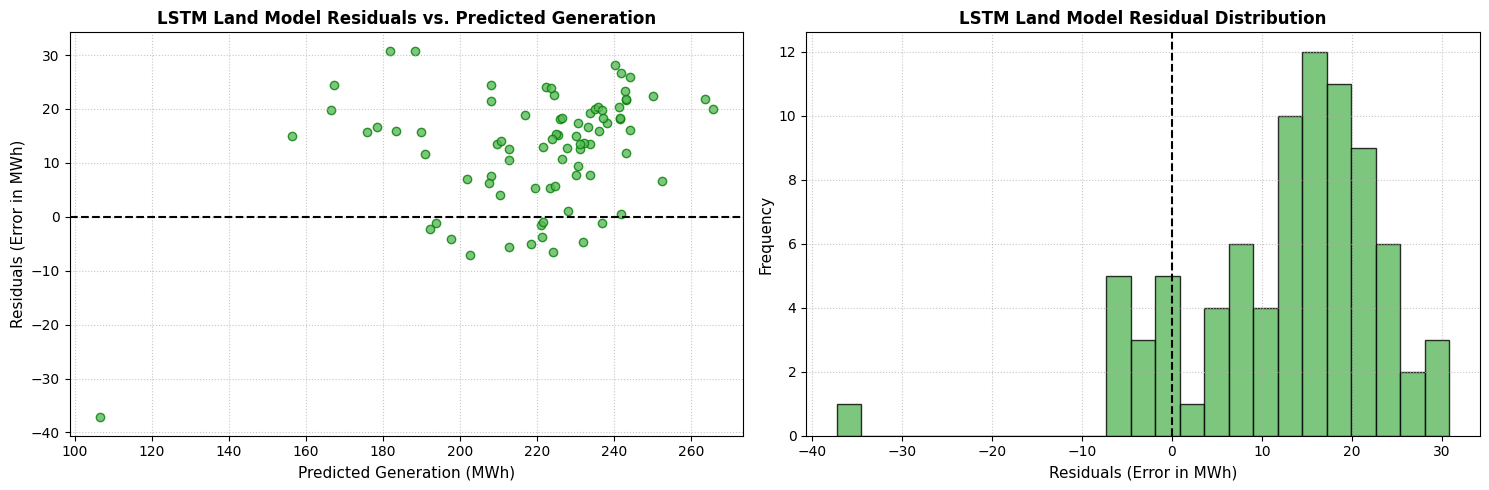

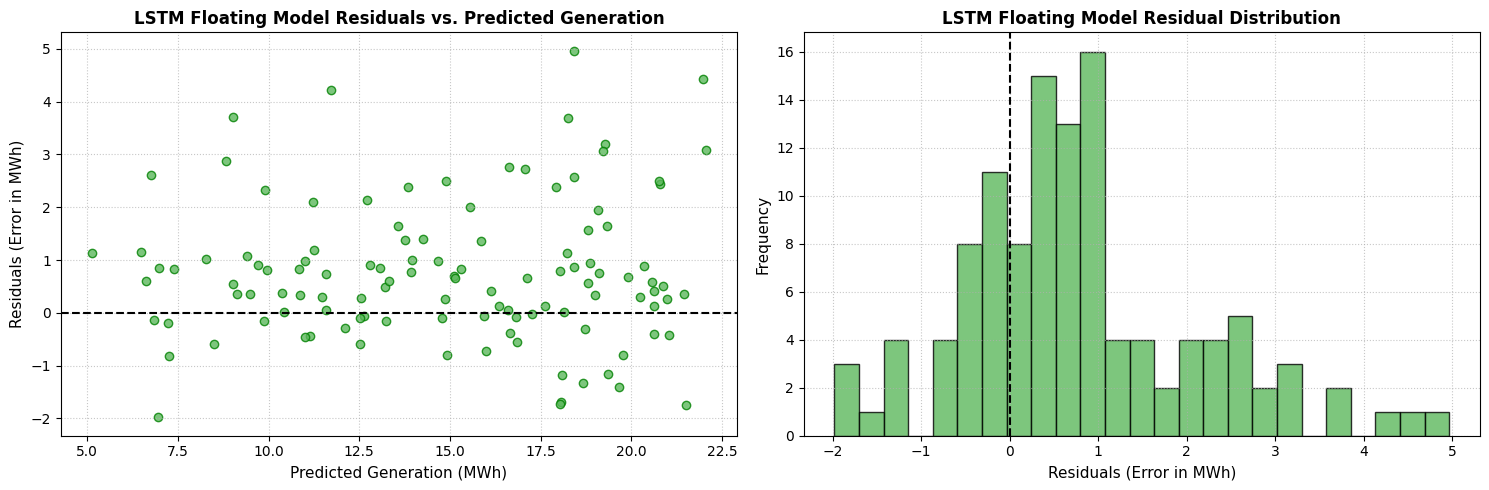

In [ ]:
import matplotlib.pyplot as plt

# Calculate Residuals (Actual - Predicted)
residuals_land = y_test_real_land - y_pred_real_land
residuals_fpv = y_test_real_fpv - y_pred_real_fpv

# -------------------------------------------------------------------
# 1. LAND PV SYSTEM: Residuals vs Predicted & Error Distribution
# -------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left Plot: Scatter (Residuals vs. Predicted Generation)
axes[0].scatter(y_pred_real_land, residuals_land, color='#5cb85c', alpha=0.8, edgecolor='green')
axes[0].axhline(0, color='black', linestyle='--', linewidth=1.5)
axes[0].set_title('LSTM Land Model Residuals vs. Predicted Generation', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Generation (MWh)', fontsize=11)
axes[0].set_ylabel('Residuals (Error in MWh)', fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.7)

# Right Plot: Histogram (Residual Distribution)
axes[1].hist(residuals_land, bins=25, color='#5cb85c', edgecolor='black', alpha=0.8)
axes[1].axvline(0, color='black', linestyle='--', linewidth=1.5)
axes[1].set_title('LSTM Land Model Residual Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residuals (Error in MWh)', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()


# -------------------------------------------------------------------
# 2. FLOATING PV SYSTEM: Residuals vs Predicted & Error Distribution
# -------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left Plot: Scatter (Residuals vs. Predicted Generation)
axes[0].scatter(y_pred_real_fpv, residuals_fpv, color='#5cb85c', alpha=0.8, edgecolor='green')
axes[0].axhline(0, color='black', linestyle='--', linewidth=1.5)
axes[0].set_title('LSTM Floating Model Residuals vs. Predicted Generation', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Generation (MWh)', fontsize=11)
axes[0].set_ylabel('Residuals (Error in MWh)', fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.7)

# Right Plot: Histogram (Residual Distribution)
axes[1].hist(residuals_fpv, bins=25, color='#5cb85c', edgecolor='black', alpha=0.8)
axes[1].axvline(0, color='black', linestyle='--', linewidth=1.5)
axes[1].set_title('LSTM Floating Model Residual Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residuals (Error in MWh)', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

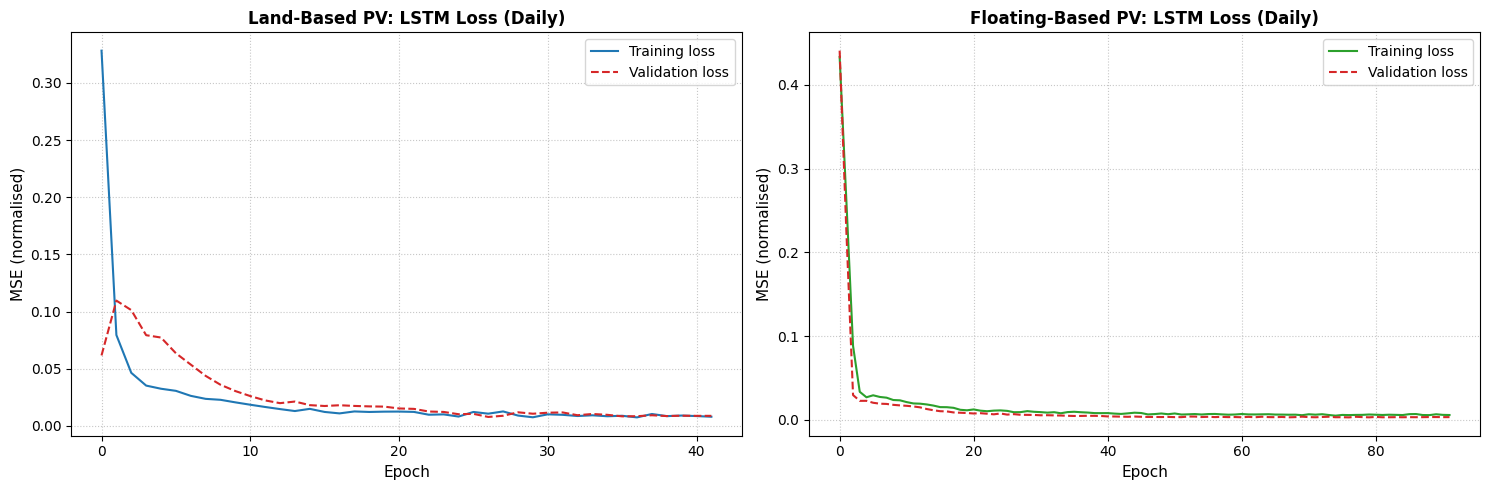

In [ ]:
import matplotlib.pyplot as plt

# Extract loss values from each model's own training history
epochs_land = range(len(history_land.history['loss']))
epochs_fpv = range(len(history_fpv.history['loss']))

# -------------------------------------------------------------------
# 1. LAND-BASED PV: Training & Validation Loss
# -------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(epochs_land, history_land.history['loss'], label='Training loss', color='#1f77b4', linewidth=1.5)
axes[0].plot(epochs_land, history_land.history['val_loss'], label='Validation loss', color='#d62728', linestyle='--', linewidth=1.5)
axes[0].set_title('Land-Based PV: LSTM Loss (Daily)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('MSE (normalised)', fontsize=11)
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle=':', alpha=0.7)

# -------------------------------------------------------------------
# 2. FLOATING-BASED PV: Training & Validation Loss
# -------------------------------------------------------------------
axes[1].plot(epochs_fpv, history_fpv.history['loss'], label='Training loss', color='#2ca02c', linewidth=1.5)
axes[1].plot(epochs_fpv, history_fpv.history['val_loss'], label='Validation loss', color='#d62728', linestyle='--', linewidth=1.5)
axes[1].set_title('Floating-Based PV: LSTM Loss (Daily)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('MSE (normalised)', fontsize=11)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()